# redes internas de las capas

In [1]:
import networkx as nx
import pandas as pd

GRAFO = "../../grafos/primekg_integrado/grafo_laboratorio/grafo"
nodos = pd.read_csv(f"{GRAFO}/nodos.csv", dtype={"node_id": str})
aristas = pd.read_csv(f"{GRAFO}/aristas.csv", dtype={"x_id": str, "y_id": str}, low_memory=False)
grupos_bert = set(nodos.loc[(nodos.node_type == "disease") & (nodos.node_source == "primekg"), "node_id"])

## Tabla
Tamaño, densidad, grado medio y componentes de cada red interna.

In [2]:
def plano(tipo, sin_grupos=False):
    sub = aristas[aristas.edge_type == tipo]
    if sin_grupos:
        sub = sub[~sub.x_id.isin(grupos_bert) & ~sub.y_id.isin(grupos_bert)]
    grafo = nx.Graph()
    grafo.add_edges_from(zip(sub.x_id, sub.y_id))
    return grafo

planos = {"genes": plano("ppi"), "enfermedades": plano("disease_disease", sin_grupos=True), "drogas": plano("drug_drug")}
filas = {}
for nombre, grafo in planos.items():
    n, m = grafo.number_of_nodes(), grafo.number_of_edges()
    tamanos = sorted((len(c) for c in nx.connected_components(grafo)), reverse=True)
    filas[nombre] = {"nodos": n, "aristas": m, "densidad": 2 * m / (n * (n - 1)), "grado medio": 2 * m / n,
                     "componentes": len(tamanos), "mayor componente": tamanos[0]}
tabla_planos = pd.DataFrame(filas).T
vista = tabla_planos.copy()
vista["densidad"] = vista.densidad.map(lambda v: f"{v:.3e}")
vista["grado medio"] = vista["grado medio"].map(lambda v: f"{v:.3f}")
for columna in ["nodos", "aristas", "componentes", "mayor componente"]:
    vista[columna] = vista[columna].astype(int)
vista

,nodos,aristas,densidad,grado medio,componentes,mayor componente
genes,13894,110051,1.140e-03,15.842,34,13819
enfermedades,5318,7836,5.543e-04,2.947,185,4644
drogas,36632,72557,1.081e-04,3.961,9485,305


## Comparaciones entre redes internas


In [4]:
pd.Series({"grado medio genes / enfermedades": tabla_planos.loc["genes", "grado medio"] / tabla_planos.loc["enfermedades", "grado medio"],
           "grado medio genes / drogas": tabla_planos.loc["genes", "grado medio"] / tabla_planos.loc["drogas", "grado medio"],
           "plano mas ralo por densidad": tabla_planos.densidad.idxmin(),
           "plano mas ralo por grado medio": tabla_planos["grado medio"].idxmin()}, dtype=object)

grado medio genes / enfermedades        5.375522
grado medio genes / drogas              3.998969
plano mas ralo por densidad               drogas
plano mas ralo por grado medio      enfermedades
dtype: object

## graficos de la CCDF de grado en las relaciones bipartitas


In [5]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

#las figuras se generan a 7 pulgadas de ancho para que LaTeX no las achique
plt.rcParams.update({"font.size": 8, "axes.titlesize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7})
colores = {"genes": "tab:blue", "enfermedades": "tab:orange", "drogas": "tab:green"}
titulos_redes = {"genes": "genes\n(interacción entre proteínas)",
                 "enfermedades": "enfermedades (jerarquía\nde MONDO sin grupos BERT)",
                 "drogas": "drogas\n(similaridad química ≥ 0,8)"}
relaciones = [("gda", "gen y enfermedad\n(GDA)", "genes", "enfermedades"),
              ("drug_gene", "droga y gen\n(bioactividad positiva)", "drogas", "genes"),
              ("drug_disease", "droga y enfermedad\n(indicación)", "drogas", "enfermedades")]

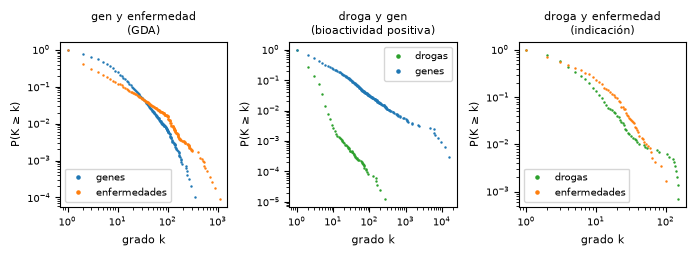

In [ ]:
figura_bipartitas, ejes = plt.subplots(1, 3, figsize=(7, 2.6))
for eje, (tipo, titulo, nombre_x, nombre_y) in zip(ejes, relaciones):
    pares = aristas[aristas.edge_type == tipo][["x_id", "y_id"]].drop_duplicates()
    #el grado de un nodo es su cantidad de vecinos del otro tipo
    for lado, nombre in [("x_id", nombre_x), ("y_id", nombre_y)]:
        grados = pares[lado].value_counts()
        #cuantos nodos tienen grado mayor o igual a cada k dividido el total
        ccdf = grados.value_counts().sort_index(ascending=False).cumsum().sort_index() / len(grados)
        eje.loglog(ccdf.index, ccdf.values, ".", markersize=1.5, color=colores[nombre], label=nombre)
    eje.set_title(titulo)
    eje.set_xlabel("grado k")
    eje.set_ylabel("P(K ≥ k)")
    eje.legend(markerscale=3)
figura_bipartitas.tight_layout()

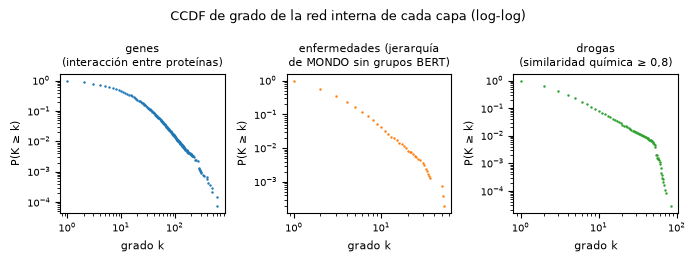

In [7]:
#un PDF de dos paginas, la 1 con las bipartitas y la 2 con las redes internas
figura_redes, ejes = plt.subplots(1, 3, figsize=(7, 2.6))
for eje, (nombre, grafo) in zip(ejes, planos.items()):
    grados = pd.Series(dict(grafo.degree()))
    ccdf = grados.value_counts().sort_index(ascending=False).cumsum().sort_index() / len(grados)
    eje.loglog(ccdf.index, ccdf.values, ".", markersize=1.5, color=colores[nombre])
    eje.set_title(titulos_redes[nombre])
    eje.set_xlabel("grado k")
    eje.set_ylabel("P(K ≥ k)")
figura_redes.suptitle("CCDF de grado de la red interna de cada capa (log-log)", fontsize=9)
figura_redes.tight_layout()

figura_bipartitas.suptitle("CCDF de grado de las relaciones bipartitas (log-log)", fontsize=9)
figura_bipartitas.tight_layout()
with PdfPages("ccdf_planos_y_capas.pdf") as pdf:
    pdf.savefig(figura_bipartitas)
    pdf.savefig(figura_redes)

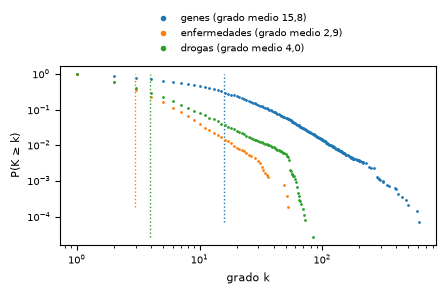

In [ ]:
figura, eje = plt.subplots(figsize=(4.5, 3))
for nombre, grafo in planos.items():
    grados = pd.Series(dict(grafo.degree()))
    ccdf = grados.value_counts().sort_index(ascending=False).cumsum().sort_index() / len(grados)
    grado_medio = f"{grados.mean():.1f}".replace(".", ",")
    eje.loglog(ccdf.index, ccdf.values, ".", markersize=2, color=colores[nombre], label=f"{nombre} (grado medio {grado_medio})")
    eje.vlines(grados.mean(), ccdf.min(), 1, color=colores[nombre], linestyle=":", linewidth=1)
eje.set_xlabel("grado k")
eje.set_ylabel("P(K ≥ k)")
eje.set_yticks([1e-4, 1e-3, 1e-2, 1e-1, 1])
eje.set_yticks([], minor=True)
#la leyenda va arriba y por fuera del cuadro para no tapar las curvas sin estirar el eje y
eje.legend(markerscale=3, loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
figura.tight_layout()
figura.savefig("ccdf_redes_internas.pdf", bbox_inches="tight")

figura_bipartitas.suptitle("")
figura_bipartitas.tight_layout()
figura_bipartitas.savefig("ccdf_bipartitas.pdf")